# Pronóstico de la demanda eléctrica nacional (SIN Colombia)
### Proyecto Integrador — Deep Learning · Primera entrega (Fase 1)

Este notebook prepara los datos, hace el análisis exploratorio (EDA) y construye la **línea base** (modelo de persistencia)
para el proyecto de pronóstico de demanda eléctrica:

> L'Heureux, A., Grolinger, K., & Capretz, M. A. M. (2022). *Transformer-Based Model for Electrical Load Forecasting*. Energies, 15(14), 4993.

Los datos usados fueron descargados con la variable **DdaReal** (demanda real) para todos los agentes del mercado, en dos
tramos: 1 de enero – 31 de diciembre de 2024, y 1 de enero – 31 de octubre de 2025.

## 1. Configuración y carga de librerías

In [19]:
# 1) Instalar la librería oficial de XM
!pip install -q pydataxm

import pandas as pd
from datetime import date
from dateutil.relativedelta import relativedelta
from pydataxm.pydataxm import ReadDB

api = ReadDB()

# Métrica y entidad (ver nota abajo)
METRICA = "DemaReal"     # demanda real
ENTIDAD = "Sistema"      # total nacional (SIN); usa "Agente" para desglose por agente

def descargar(inicio, fin):
    """Descarga por bloques mensuales para respetar el límite de la API."""
    frames = []
    cur = inicio
    while cur <= fin:
        fin_mes = min(cur + relativedelta(months=1) - relativedelta(days=1), fin)
        for intento in range(3):
            try:
                df = api.request_data(METRICA, ENTIDAD, cur, fin_mes)
                if df is not None and len(df):
                    frames.append(df)
                break
            except Exception as e:
                print(f"Reintento {intento+1} para {cur}: {e}")
        cur = fin_mes + relativedelta(days=1)
    return pd.concat(frames, ignore_index=True)

PATH_2024 = "demanda_real_2024.csv"
PATH_2025 = "demanda_real_2025.csv"

df24 = descargar(date(2024, 1, 1), date(2024, 12, 31))
df25 = descargar(date(2025, 1, 1), date(2025, 10, 31))

df24.to_csv(PATH_2024, index=False)
df25.to_csv(PATH_2025, index=False)

print(df24.shape, df25.shape)
df24.head()

(366, 27) (304, 27)


,Id,Values_code,Values_Hour01,Values_Hour02,Values_Hour03,Values_Hour04,Values_Hour05,Values_Hour06,Values_Hour07,Values_Hour08,...,Values_Hour16,Values_Hour17,Values_Hour18,Values_Hour19,Values_Hour20,Values_Hour21,Values_Hour22,Values_Hour23,Values_Hour24,Date
0,Sistema,Sistema,7236893.31000,7104164.61000,7012446.40000,6870115.23000,6759771.97000,6671795.60000,6287595.26000,6319646.62000,...,7335829.33000,7316670.59000,7381571.21000,8108189.21000,8336059.98000,8268100.14000,8106656.06000,7833804.62000,7518276.26000,2024-01-01
1,Sistema,Sistema,7235609.90000,7008752.02000,6849053.28000,6778829.26000,6832928.86000,7000995.55000,7119165.29000,7575100.32000,...,9559801.66000,9384656.76000,9181488.18000,9714483.87000,9846198.13000,9792471.23000,9425189.28000,8960022.36000,8415379.52000,2024-01-02
2,Sistema,Sistema,7910813.60000,7601383.44000,7413135.40000,7300902.81000,7353161.64000,7517283.16000,7603462.66000,8113123.05000,...,9816960.58000,9688066.47000,9452703.16000,10012567.59000,10134511.35000,9924236.86000,9584538.04000,9098400.50000,8586118.91000,2024-01-03
3,Sistema,Sistema,8152073.46000,7853237.05000,7630373.44000,7503826.33000,7542402.67000,7686266.86000,7783356.20000,8313125.49000,...,10012832.09000,9914358.14000,9677403.07000,10223460.32000,10314986.15000,10095536.41000,9741285.98000,9263915.53000,8749248.40000,2024-01-04
4,Sistema,Sistema,8310027.77000,7990135.69000,7750118.97000,7625441.15000,7663890.28000,7826647.15000,7935980.98000,8414657.00000,...,10036089.58000,9866169.23000,9636698.05000,10171551.23000,10238555.65000,10039293.14000,9704757.95000,9242822.11000,8723548.39000,2024-01-05


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({'font.size': 11, 'axes.grid': True, 'grid.alpha': 0.3, 'figure.dpi': 110})

PATH_2024 = "Demandarealnacional894b4c1f-5776-421b-8f14-7cbfe8677e23.csv"  # 1 ene - 31 dic 2024
PATH_2025 = "Demandarealnacional5f838d41-8d2e-4e07-ac1a-52ee7c89d340.csv"  # 1 ene - 31 oct 2025


## 2. Carga y limpieza de los datos

Los archivos de XM traen la demanda **desagregada por 65 agentes** del mercado (regulado y no regulado), y para
un mismo mes pueden existir **varias versiones de liquidación** (`TX2` … `TX8`, `TXR`, `TXF`), que corresponden a
sucesivas revisiones que hace XM sobre el mismo periodo. Si no filtramos por versión, sumaríamos la misma hora varias
veces.

La estrategia es: para cada mes, quedarnos únicamente con la versión **más avanzada** disponible (dando prioridad a la
versión final `TXF` cuando existe), y luego sumar la demanda de los 65 agentes por hora para obtener la
**demanda nacional horaria**.

In [ ]:
df = pd.concat([pd.read_csv(PATH_2024), pd.read_csv(PATH_2025)], ignore_index=True)
df['FechaHora'] = pd.to_datetime(df['FechaHora'])
df['mes'] = df['FechaHora'].dt.to_period('M')

print(f"Filas totales cargadas: {len(df):,}")
print(f"Agentes de mercado distintos: {df['CodigoSICAgente'].nunique()}")
print(f"Versiones de liquidación presentes: {sorted(df['Version'].unique())}")
df.head()


In [4]:
# Prioridad de versiones: la más final primero
prioridad = ['TXF', 'TXR', 'TX8', 'TX7', 'TX6', 'TX5', 'TX4', 'TX3', 'TX2']
rango = {v: i for i, v in enumerate(prioridad)}
df['rango'] = df['Version'].map(rango)

# Para cada mes, se identifica la mejor version disponible (menor rango) y se filtra
mejor_por_mes = df.groupby('mes')['rango'].min().rename('mejor_rango')
df = df.merge(mejor_por_mes, on='mes')
df_limpio = df[df['rango'] == df['mejor_rango']].copy()

print("Version seleccionada por mes:")
print(df_limpio.groupby('mes')['Version'].unique())
print(f"\nFilas tras eliminar versiones duplicadas: {len(df_limpio):,} (de {len(df):,} originales)")


Version seleccionada por mes:
mes
2024-01    [TX5]
2024-02    [TX6]
2024-03    [TX6]
2024-04    [TX5]
2024-05    [TX4]
2024-06    [TX5]
2024-07    [TX5]
2024-08    [TX4]
2024-09    [TX8]
2024-10    [TX7]
2024-11    [TX7]
2024-12    [TX7]
2025-01    [TX4]
2025-02    [TX4]
2025-03    [TX4]
2025-04    [TX5]
2025-05    [TX4]
2025-06    [TX3]
2025-07    [TX5]
2025-08    [TXF]
2025-09    [TXF]
2025-10    [TXF]
Freq: M, Name: Version, dtype: object

Filas tras eliminar versiones duplicadas: 1,436,328 (de 2,257,704 originales)


In [5]:
# Se suma la demanda de los 65 agentes por hora -> demanda nacional horaria
nacional = df_limpio.groupby('FechaHora')['Valor'].sum().reset_index()
nacional.columns = ['FechaHora', 'DemandaKWh']
nacional = nacional.sort_values('FechaHora').reset_index(drop=True)
nacional['DemandaMWh'] = nacional['DemandaKWh'] / 1000

# Verificacion de continuidad: no deben faltar horas
rango_completo = pd.date_range(nacional['FechaHora'].min(), nacional['FechaHora'].max(), freq='h')
faltantes = rango_completo.difference(nacional['FechaHora'])
print(f"Periodo: {nacional['FechaHora'].min()} a {nacional['FechaHora'].max()}")
print(f"Horas totales: {len(nacional):,}  |  Horas faltantes: {len(faltantes)}")

nacional.to_csv('demanda_nacional_horaria.csv', index=False)
nacional.describe()


Periodo: 2024-01-01 00:00:00 a 2025-10-31 23:00:00
Horas totales: 16,080  |  Horas faltantes: 0


,FechaHora,DemandaKWh,DemandaMWh
count,16080,1.608000e+04,16080.000000
mean,2024-11-30 23:30:00,9.257954e+06,9257.954059
min,2024-01-01 00:00:00,6.224061e+06,6224.061460
25%,2024-06-16 11:45:00,8.318539e+06,8318.538558
50%,2024-11-30 23:30:00,9.315562e+06,9315.562110
75%,2025-05-17 11:15:00,1.023415e+07,10234.152555
max,2025-10-31 23:00:00,1.166771e+07,11667.714170
std,NaN,1.090829e+06,1090.828563


## 3. Análisis exploratorio (EDA)

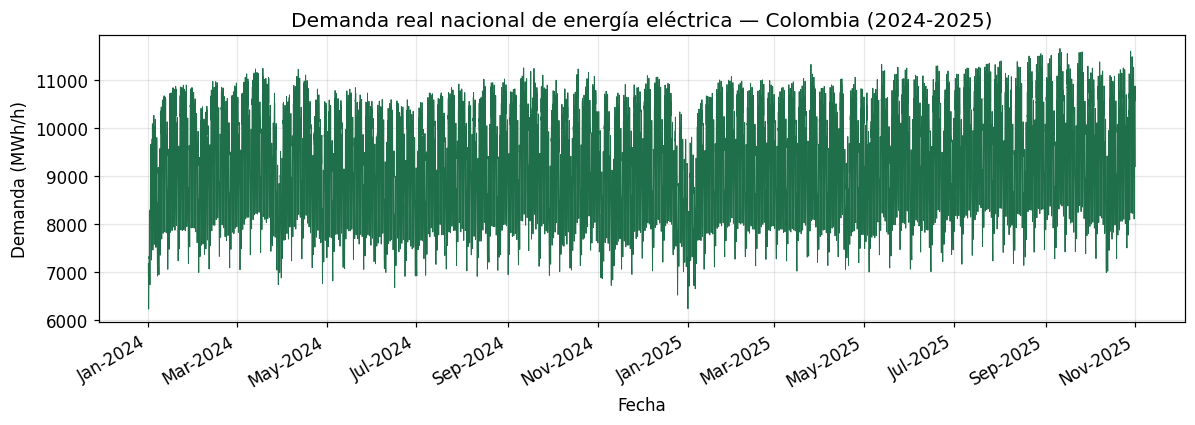

In [6]:
df_idx = nacional.set_index('FechaHora')
y = df_idx['DemandaMWh']

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(y.index, y.values, color='#1f6f4a', linewidth=0.6)
ax.set_title('Demanda real nacional de energía eléctrica — Colombia (2024-2025)')
ax.set_ylabel('Demanda (MWh/h)')
ax.set_xlabel('Fecha')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b-%Y'))
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig('fig1_serie_completa.png', dpi=160)
plt.show()


Se observa una estacionalidad diaria muy marcada (el rango entre el valle nocturno y el pico) y un **crecimiento
gradual** de la demanda entre 2024 y 2025, con una caída puntual muy fuerte alrededor de año nuevo (1 de enero,
festivo con demanda mínima del periodo).

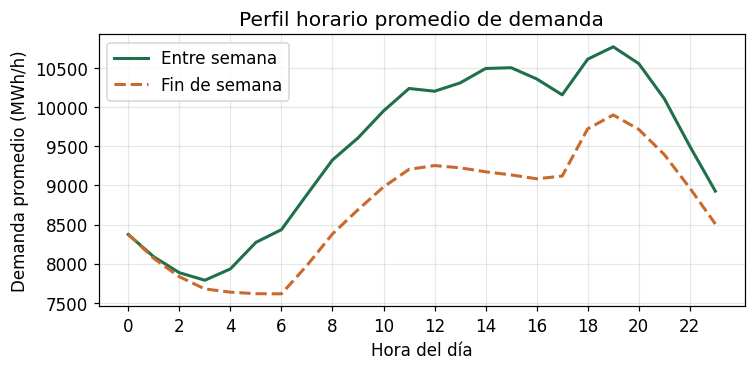

In [7]:
# Perfil horario promedio: entre semana vs fin de semana
tmp = df_idx.copy()
tmp['hora'] = tmp.index.hour
tmp['dow'] = tmp.index.dayofweek  # 0 = lunes
tmp['tipo_dia'] = np.where(tmp['dow'] < 5, 'Entre semana', 'Fin de semana')
perfil = tmp.groupby(['tipo_dia', 'hora'])['DemandaMWh'].mean().unstack(0)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(perfil.index, perfil['Entre semana'], label='Entre semana', color='#1f6f4a', linewidth=2)
ax.plot(perfil.index, perfil['Fin de semana'], label='Fin de semana', color='#c96a2b', linewidth=2, linestyle='--')
ax.set_title('Perfil horario promedio de demanda')
ax.set_xlabel('Hora del día'); ax.set_ylabel('Demanda promedio (MWh/h)')
ax.set_xticks(range(0, 24, 2)); ax.legend()
plt.tight_layout()
plt.savefig('fig2_perfil_horario.png', dpi=160)
plt.show()


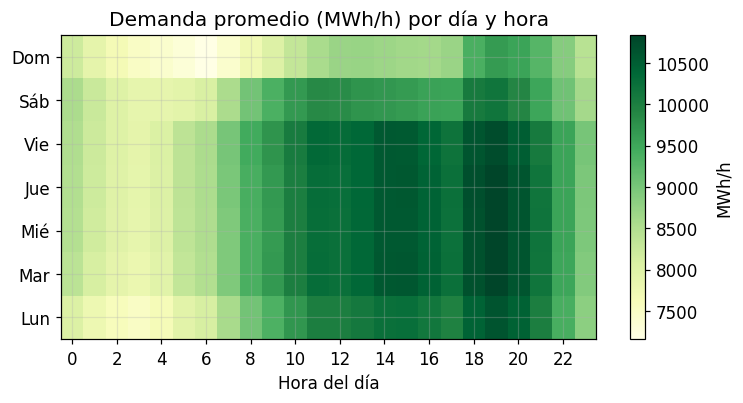

In [8]:
# Mapa de calor dia de la semana x hora
dias_es = ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']
heat = tmp.groupby(['dow', 'hora'])['DemandaMWh'].mean().unstack(0)

fig, ax = plt.subplots(figsize=(7, 3.8))
im = ax.imshow(heat.T.values, aspect='auto', cmap='YlGn', origin='lower')
ax.set_yticks(range(7)); ax.set_yticklabels(dias_es)
ax.set_xticks(range(0, 24, 2)); ax.set_xticklabels(range(0, 24, 2))
ax.set_xlabel('Hora del día'); ax.set_title('Demanda promedio (MWh/h) por día y hora')
cbar = plt.colorbar(im, ax=ax); cbar.set_label('MWh/h')
plt.tight_layout()
plt.savefig('fig3_heatmap_dia_hora.png', dpi=160)
plt.show()


**Lectura:** la demanda es más alta entre semana que los fines de semana, con un pico consistente entre las 6 p. m. y
las 8 p. m. (hora de mayor consumo residencial + comercial/industrial aún activo) y un valle en la madrugada (2-5 a. m.).
Estos dos patrones diario y semanal son justamente el tipo de señal de calendario que el módulo contextual del
artículo Transformer está diseñado para aprovechar.

## 4. Partición cronológica (train / test)

Para evitar fuga de información desde el futuro, la partición es estrictamente cronológica: las últimas 8 semanas
se reservan para prueba, y todo lo anterior se usa como entrenamiento (en la Fase 2 se separará además un bloque de
validación desde el final del entrenamiento).

In [9]:
TEST_DIAS = 56  # 8 semanas
test_start = df_idx.index.max() - pd.Timedelta(days=TEST_DIAS)

train = df_idx[df_idx.index < test_start]
test = df_idx[df_idx.index >= test_start]

print(f"Entrenamiento: {train.index.min()} -> {train.index.max()}  ({len(train):,} horas)")
print(f"Prueba:        {test.index.min()} -> {test.index.max()}  ({len(test):,} horas)")


Entrenamiento: 2024-01-01 00:00:00 -> 2025-09-05 22:00:00  (14,735 horas)
Prueba:        2025-09-05 23:00:00 -> 2025-10-31 23:00:00  (1,345 horas)


## 5. Línea base: modelo de persistencia

Se evalúan tres variantes:

- **Persistencia t-1h**: la demanda de la próxima hora es igual a la de la hora inmediatamente anterior.
- **Persistencia t-24h** (línea base oficial): la demanda de una hora es igual a la de la misma hora del día anterior.
- **Persistencia t-168h**: la demanda de una hora es igual a la de la misma hora, mismo día, de la semana anterior.

Las métricas usadas MAE, RMSE y MAPE son las mismas que reporta el artículo base.

In [10]:
def metricas(y_true, y_pred):
    err = y_true - y_pred
    mae = err.abs().mean()
    rmse = np.sqrt((err ** 2).mean())
    mape = (err.abs() / y_true.abs()).mean() * 100
    return mae, rmse, mape

pred_1 = y.shift(1)
pred_24 = y.shift(24)
pred_168 = y.shift(168)

mask_test = test.index
b1 = metricas(y.loc[mask_test], pred_1.loc[mask_test])
b24 = metricas(y.loc[mask_test], pred_24.loc[mask_test])
b168 = metricas(y.loc[mask_test], pred_168.loc[mask_test])

resultados = pd.DataFrame(
    [b1, b24, b168],
    columns=['MAE (MWh)', 'RMSE (MWh)', 'MAPE (%)'],
    index=['Persistencia t-1h', 'Persistencia t-24h (línea base oficial)', 'Persistencia t-168h']
).round(2)
resultados


,MAE (MWh),RMSE (MWh),MAPE (%)
Persistencia t-1h,274.04,329.57,2.92
Persistencia t-24h (línea base oficial),433.54,633.57,4.59
Persistencia t-168h,283.03,390.96,3.02


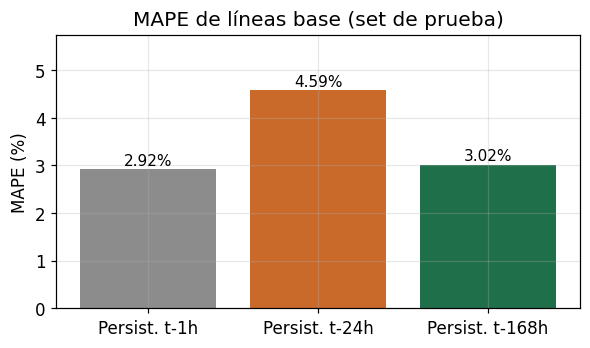

In [11]:
labels = ['Persist. t-1h', 'Persist. t-24h', 'Persist. t-168h']
mapes = [b1[2], b24[2], b168[2]]

fig, ax = plt.subplots(figsize=(5.5, 3.3))
bars = ax.bar(labels, mapes, color=['#8c8c8c', '#c96a2b', '#1f6f4a'])
ax.set_ylabel('MAPE (%)')
ax.set_title('MAPE de líneas base (set de prueba)')
ax.set_ylim(0, max(mapes) * 1.25)
for bar, v in zip(bars, mapes):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.08, f'{v:.2f}%', ha='center', fontsize=10)
plt.tight_layout()
plt.savefig('fig5_mape_baselines.png', dpi=160)
plt.show()


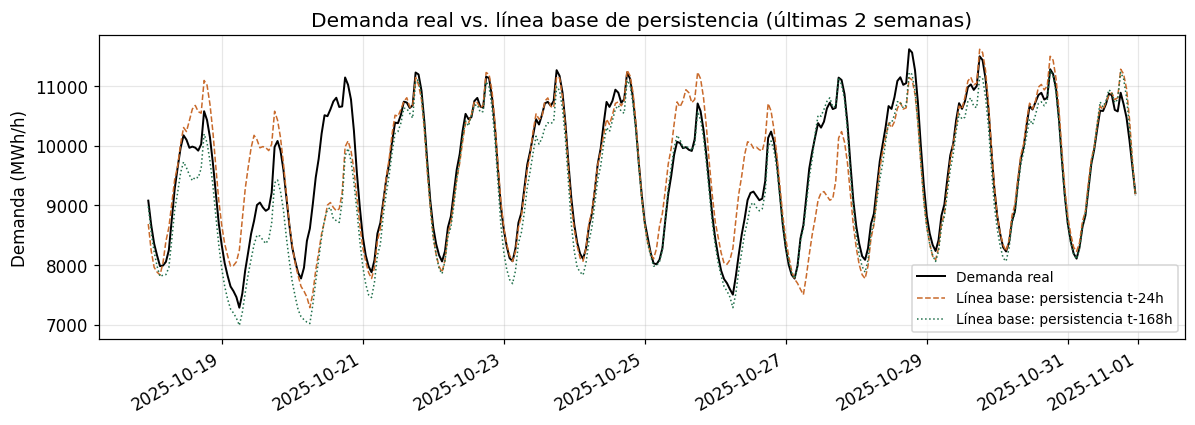

In [12]:
zoom = df_idx.index >= (df_idx.index.max() - pd.Timedelta(days=14))

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(y.index[zoom], y.values[zoom], label='Demanda real', color='black', linewidth=1.3)
ax.plot(y.index[zoom], pred_24.values[zoom], label='Línea base: persistencia t-24h', color='#c96a2b', linewidth=1, linestyle='--')
ax.plot(y.index[zoom], pred_168.values[zoom], label='Línea base: persistencia t-168h', color='#1f6f4a', linewidth=1, linestyle=':')
ax.set_title('Demanda real vs. línea base de persistencia (últimas 2 semanas)')
ax.set_ylabel('Demanda (MWh/h)')
ax.legend(fontsize=9)
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig('fig4_baseline_zoom.png', dpi=160)
plt.show()


**Conclusión de la línea base:** la persistencia semanal (t-168h) es notablemente más precisa (MAPE ≈ 3.0 %) que la
persistencia diaria (t-24h, MAPE ≈ 4.6 %), lo que confirma que el patrón semana/fin de semana es muy fuerte en esta
serie. Se adopta **t-24h como línea base oficial** por ser la sugerida explícitamente en la guía del curso para un
horizonte de 24 horas, y se deja t-168h como referencia adicional de contraste.


## 6. Resumen de estadísticas para el informe

In [13]:
df_idx['anio'] = df_idx.index.year
df_idx['mes_num'] = df_idx.index.month
comparable = df_idx[df_idx['mes_num'] <= 10]  # enero-octubre en ambos años
promedio_anual = comparable.groupby('anio')['DemandaMWh'].mean()
crecimiento = (promedio_anual[2025] / promedio_anual[2024] - 1) * 100

print(f"Horas totales en la serie: {len(df_idx):,}  ({len(df_idx)/24:.0f} días)")
print(f"Demanda promedio: {y.mean():,.0f} MWh/h")
print(f"Demanda mínima:   {y.min():,.0f} MWh/h  el {y.idxmin()}")
print(f"Demanda máxima:   {y.max():,.0f} MWh/h  el {y.idxmax()}")
print(f"Crecimiento demanda promedio ene-oct 2025 vs. 2024: {crecimiento:.1f}%")


Horas totales en la serie: 16,080  (670 días)
Demanda promedio: 9,258 MWh/h
Demanda mínima:   6,224 MWh/h  el 2024-01-01 06:00:00
Demanda máxima:   11,668 MWh/h  el 2025-09-10 19:00:00
Crecimiento demanda promedio ene-oct 2025 vs. 2024: 2.0%


#Segunda Entrega

In [14]:
!pip -q install holidays
import time, copy, numpy as np, pandas as pd, holidays
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Usando:', dev)

PATH_GEF   = 'Load_history.csv'                 # conjunto original (GEFCom2012)
PATH_LOCAL = 'demanda_nacional_horaria.csv'     # conjunto local (Fase 1)

L, H = 24, 24            # ventana de entrada y horizonte (horas): una de las combinaciones del artículo
D, HEADS, CAPAS = 32, 2, 2   # Transformer reducido: 2 codificadores, 2 decodificadores, 2 cabezas (como el artículo)
SEMILLAS = [0, 1, 2, 3, 4]   # 5 repeticiones para medir la variabilidad
MAX_EP_SRC, MAX_EP_LOC, PACIENCIA = 30, 80, 8
STRIDE_SRC = 6           # versión reducida: una ventana cada 6 h en GEFCom (el artículo usa todas)
plt.rcParams.update({'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.3, 'figure.dpi': 110})

Usando: cpu


## 1. Funciones comunes
Todo se hace igual en los dos conjuntos: **ventanas** de 24 h de entrada → 24 h de salida, con variables de calendario
(hora, día de la semana, fin de semana/festivo), tal como propone el artículo.

In [15]:
def calendario(idx, pais):
    # 4 variables de calendario conocidas de antemano
    fest = holidays.country_holidays(pais, years=sorted(set(idx.year)))
    es_fest = idx.normalize().isin(pd.to_datetime(list(fest.keys())))
    no_lab = ((idx.dayofweek >= 5) | es_fest).astype(float)
    return np.c_[np.sin(2*np.pi*idx.hour/24), np.cos(2*np.pi*idx.hour/24), idx.dayofweek/6, no_lab].astype('float32')

class Ventanas:
    # Guarda (serie, tiempo) de cada ventana y arma los lotes al vuelo
    def __init__(s, S, cal, ini, fin, stride):
        # S: (n_series, T) normalizada | las ventanas tienen su salida dentro de [ini, fin)
        ts = np.arange(max(ini, L), fin - H + 1, stride)
        s.t = np.tile(ts, len(S)); s.sid = np.repeat(np.arange(len(S)), len(ts))
        s.S = torch.tensor(S, dtype=torch.float32, device=dev); s.C = torch.tensor(cal, device=dev)
    def __len__(s): return len(s.t)
    def get(s, ids):
        t = torch.tensor(s.t[ids], device=dev); sid = torch.tensor(s.sid[ids], device=dev)
        ix = t[:, None] + torch.arange(-L, H, device=dev)[None]
        v, c = s.S[sid[:, None], ix], s.C[ix]
        return v[:, :L, None], c[:, :L], c[:, L:], v[:, L:]     # x, calendario_x, calendario_y, y

def lotes(W, bs=256, mezclar=False):
    ids = np.random.permutation(len(W)) if mezclar else np.arange(len(W))
    for i in range(0, len(ids), bs): yield ids[i:i+bs]

# Modelos
class TransformerCarga(nn.Module):
    # Versión reducida del artículo: módulo contextual + espacio N + codificador-decodificador
    def __init__(s, ncal=4, d=D):
        super().__init__()
        s.carga, s.cal = nn.Linear(1, d), nn.Linear(ncal, d)      # módulo contextual: carga y calendario por separado
        s.espN = nn.Linear(2*d, d)                                # "espacio N": los combina linealmente
        s.cal_dec = nn.Linear(ncal, d)                            # el decodificador recibe el calendario del futuro
        s.pos_e, s.pos_d = nn.Parameter(torch.randn(L, d)*.02), nn.Parameter(torch.randn(H, d)*.02)
        s.transformer = nn.Transformer(d, HEADS, CAPAS, CAPAS, 2*d, 0.1, batch_first=True)
        s.salida = nn.Linear(d, 1)
    def forward(s, x, cx, cy):
        e = s.espN(torch.cat([s.carga(x), s.cal(cx)], -1)) + s.pos_e
        h = s.transformer.decoder(s.cal_dec(cy) + s.pos_d, s.transformer.encoder(e))
        return s.salida(h).squeeze(-1)
    def grupos(s):   # partes del modelo, para congelar / usar tasas de aprendizaje distintas
        enc = [*s.carga.parameters(), *s.cal.parameters(), *s.espN.parameters(), s.pos_e, *s.transformer.encoder.parameters()]
        dec = [*s.cal_dec.parameters(), s.pos_d, *s.transformer.decoder.parameters()]
        return enc, dec, list(s.salida.parameters())

class Seq2SeqGRU(nn.Module):
    # Modelo de referencia del artículo (versión simple, sin atención)
    def __init__(s, ncal=4, d=D):
        super().__init__()
        s.enc, s.dec, s.salida = nn.GRU(1+ncal, d, batch_first=True), nn.GRU(ncal, d, batch_first=True), nn.Linear(d, 1)
    def forward(s, x, cx, cy):
        _, h = s.enc(torch.cat([x, cx], -1)); o, _ = s.dec(cy, h)
        return s.salida(o).squeeze(-1)
    def grupos(s):
        return list(s.enc.parameters()), list(s.dec.parameters()), list(s.salida.parameters())

# Entrenamiento con parada temprana
def entrenar(m, grupos_opt, Wtr, Wva, max_ep, semilla):
    torch.manual_seed(semilla); np.random.seed(semilla)
    opt = torch.optim.Adam(grupos_opt)
    mejor, estado, sin_mej, h = 1e9, None, 0, dict(train=[], val=[], grad=[])
    t0 = time.time()
    for ep in range(max_ep):
        m.train(); perd, gr = [], []
        for ids in lotes(Wtr, 256, True):
            x, cx, cy, y = Wtr.get(ids)
            loss = F.mse_loss(m(x, cx, cy), y)
            opt.zero_grad(); loss.backward()
            gr.append(nn.utils.clip_grad_norm_(m.parameters(), 1.0).item())   # norma del gradiente (antes de recortar)
            opt.step(); perd.append(loss.item())
        va = perdida(m, Wva)
        h['train'].append(np.mean(perd)); h['val'].append(va); h['grad'].append(np.mean(gr))
        if va < mejor - 1e-6: mejor, estado, sin_mej = va, copy.deepcopy(m.state_dict()), 0
        else:
            sin_mej += 1
            if sin_mej >= PACIENCIA: break          # criterio de parada: val no mejora en PACIENCIA épocas
    m.load_state_dict(estado)
    h.update(mejor_ep=int(np.argmin(h['val'])) + 1, epocas=len(h['val']), seg=time.time() - t0)
    return h

@torch.no_grad()
def predecir(m, W):
    m.eval(); P = []
    for ids in lotes(W, 1024):
        x, cx, cy, y = W.get(ids); P.append(m(x, cx, cy))
    return torch.cat(P).cpu().numpy()

def perdida(m, W):
    P = predecir(m, W); Y = np.concatenate([W.get(ids)[3].cpu().numpy() for ids in lotes(W, 1024)])
    return float(((P - Y)**2).mean())

def evaluar(m, W, mn, rg):
    # Métricas en la escala original. mn, rg: mínimo y rango de cada serie (para des-normalizar)
    P = predecir(m, W); X = np.concatenate([W.get(i)[0].cpu().numpy()[..., 0] for i in lotes(W, 1024)])
    Y = np.concatenate([W.get(i)[3].cpu().numpy() for i in lotes(W, 1024)])
    a, b = mn[W.sid][:, None], rg[W.sid][:, None]
    P, X, Y = P*b + a, X*b + a, Y*b + a
    mape = lambda p: np.abs(Y - p) / np.abs(Y) * 100
    por_serie = pd.Series(mape(P).mean(1)).groupby(W.sid).mean()
    return dict(MAE=np.abs(Y-P).mean(), RMSE=np.sqrt(((Y-P)**2).mean()), MAPE=mape(P).mean(),
                MAPE_base24=mape(X).mean(),            # persistencia t-24h = la ventana de entrada
                MAPE_series=por_serie.values)

## 2. Fase 7.1 Replicación sobre GEFCom2012 (conjunto original)
Se cargan las 20 zonas, se rellenan huecos por interpolación y se normaliza **cada zona con su propio mínimo y máximo
calculados solo con el entrenamiento**. La partición es cronológica: **test = últimos 6 meses, validación = 6 meses anteriores**.

In [16]:
raw = pd.read_csv(PATH_GEF, thousands=',')
raw = raw[raw['zone_id'] <= 20]
raw['fecha'] = pd.to_datetime(raw[['year', 'month', 'day']])
largo = raw.melt(id_vars=['zone_id', 'fecha'], value_vars=[f'h{i}' for i in range(1, 25)], var_name='h', value_name='carga')
largo['FechaHora'] = largo['fecha'] + pd.to_timedelta(largo['h'].str[1:].astype(int) - 1, unit='h')
G = largo.pivot_table(index='FechaHora', columns='zone_id', values='carga')
G = G.reindex(pd.date_range(G.index.min(), G.index.max(), freq='h')).interpolate(limit_direction='both')
print(f'GEFCom2012: {G.shape[1]} zonas, {len(G):,} horas ({G.index.min().date()} a {G.index.max().date()})')

T = len(G); te_ini = T - 180*24; va_ini = te_ini - 180*24          # particiones cronológicas
mn_g, rg_g = G.iloc[:va_ini].min().values, (G.iloc[:va_ini].max() - G.iloc[:va_ini].min()).values   # solo train
Sg = ((G.values - mn_g) / rg_g).T
cal_g = calendario(G.index, 'US')
Wtr_g = Ventanas(Sg, cal_g, 0, va_ini, STRIDE_SRC)
Wva_g = Ventanas(Sg, cal_g, va_ini, te_ini, STRIDE_SRC)
Wte_g = Ventanas(Sg, cal_g, te_ini, T, 24)
print('Ventanas train/val/test:', len(Wtr_g), len(Wva_g), len(Wte_g))

GEFCom2012: 20 zonas, 39,414 horas (2004-01-01 a 2008-06-30)
Ventanas train/val/test: 102440 14340 3600


In [21]:
res_src, pre = {}, {}
for nombre, Clase in [('Transformer', TransformerCarga), ('Seq2Seq-GRU', Seq2SeqGRU)]:
    m = Clase().to(dev)
    h = entrenar(m, [{'params': list(m.parameters()), 'lr': 1e-3}], Wtr_g, Wva_g, MAX_EP_SRC, semilla=0)
    r = evaluar(m, Wte_g, mn_g, rg_g); r.update(epocas=h['epocas'], seg=h['seg']); res_src[nombre] = r
    pre[nombre] = copy.deepcopy(m.state_dict())
    print(f"{nombre:12s} MAPE promedio de 20 zonas = {r['MAPE']:.2f}% | mediana por zona = {np.median(r['MAPE_series']):.2f}% | "
          f"{h['epocas']} épocas, {h['seg']:.0f} s")
torch.save(pre['Transformer'], 'pre_transformer.pt')

print(f"\nPersistencia t-24h (referencia): {res_src['Transformer']['MAPE_base24']:.2f}%")
dif = res_src['Seq2Seq-GRU']['MAPE'] - res_src['Transformer']['MAPE']
print(f"Diferencia GRU - Transformer: {dif:+.2f} puntos de MAPE  (el artículo reporta ~1.2 puntos a favor del Transformer)")

Transformer  MAPE promedio de 20 zonas = 12.62% | mediana por zona = 10.02% | 20 épocas, 1900 s
Seq2Seq-GRU  MAPE promedio de 20 zonas = 12.67% | mediana por zona = 10.23% | 30 épocas, 425 s

Persistencia t-24h (referencia): 14.10%
Diferencia GRU - Transformer: +0.05 puntos de MAPE  (el artículo reporta ~1.2 puntos a favor del Transformer)


compara la *dirección* ¿gana el Transformer? y el *orden de magnitud* de la diferencia con lo
que reportan los autores. No se espera el mismo número exacto, porque esta es una versión reducida (d=32, una ventana cada 6 h,
máx. 30 épocas, 1 semilla, ventana 24→24 y decodificador no autoregresivo en vez de *teacher forcing* adaptativo).

## 3. Fase 7.2 — Traslado al problema local (Colombia)
Cambios por el cambio de dominio: una sola serie nacional (MWh/h en vez de kW por zona), calendario y festivos de **Colombia**
(`holidays.CO`), y las mismas particiones de la entrega 1: **test = últimas 8 semanas**; **validación = 8 semanas anteriores**;
entrenamiento = todo lo previo. La normalización usa solo datos de entrenamiento, y las ventanas de entrada de
validación/test solo miran al pasado, así que **no hay fuga de información**.

In [22]:
loc = pd.read_csv(PATH_LOCAL, parse_dates=['FechaHora']).set_index('FechaHora')['DemandaMWh']
n = len(loc); n_te = int((loc.index >= loc.index.max() - pd.Timedelta(days=56)).sum())   # igual que la entrega 1 (1.345 h)
te_l = n - n_te; va_l = te_l - 56*24
mn_l, rg_l = np.array([loc.iloc[:va_l].min()]), np.array([loc.iloc[:va_l].max() - loc.iloc[:va_l].min()])
Sl = ((loc.values - mn_l) / rg_l)[None]
cal_l = calendario(loc.index, 'CO')
Wtr_l = Ventanas(Sl, cal_l, 0, va_l, 1)
Wva_l = Ventanas(Sl, cal_l, va_l, te_l, 1)
Wte_l = Ventanas(Sl, cal_l, te_l, n, 24)       # ventanas sin solape: 56 días de 24 h
print(f'Train {loc.index[0]} -> {loc.index[va_l-1]} | Val -> {loc.index[te_l-1]} | Test -> {loc.index[-1]}')
print('Ventanas train/val/test:', len(Wtr_l), len(Wva_l), len(Wte_l))

# Distancia entre dominios: ¿qué tan parecido es el perfil diario promedio?
# NOTA: Comentado porque se omitió la carga previa de GEFCom2012 (Sg y G no están definidos)
# perfil = lambda S, idx: pd.DataFrame(S.T, index=idx).groupby(idx.hour).mean().mean(axis=1)
# corr = np.corrcoef(perfil(Sg, G.index), perfil(Sl, loc.index))[0, 1]
# print(f'Correlación del perfil horario normalizado GEFCom vs Colombia: {corr:.2f}')

Train 2024-01-01 00:00:00 -> 2025-07-11 22:00:00 | Val -> 2025-09-05 22:00:00 | Test -> 2025-10-31 23:00:00
Ventanas train/val/test: 13344 1321 56


## 4. Estrategia de transferencia
Se parte del Transformer preentrenado en GEFCom2012 y se prueban 4 formas de usarlo en Colombia:

| Configuración | Qué se entrena | Tasa de aprendizaje |
|---|---|---|
| **Desde cero** | todo (sin preentrenamiento) | 1e-3 |
| **Extractor congelado** | solo la capa de salida | 1e-3 |
| **Fine-tuning parcial** | decodificador + salida (codificador congelado) | decodificador 1e-4, salida 1e-3 |
| **Fine-tuning total** | todo, con tasas diferenciadas | codificador 1e-5, decodificador 1e-4, salida 1e-3 |

Criterio de parada: la pérdida de validación no mejora en 8 épocas (se restaura el mejor modelo).
**La mejor configuración se elige con la validación, no con el test.** También se entrena el Seq2Seq-GRU como contraste.

In [24]:
def preparar(m, modo):
    enc, dec, cab = m.grupos()
    cfg = {'Desde cero': [(enc, 1e-3), (dec, 1e-3), (cab, 1e-3)],
           'Extractor congelado': [(cab, 1e-3)],
           'Fine-tuning parcial': [(dec, 1e-4), (cab, 1e-3)],
           'Fine-tuning total': [(enc, 1e-5), (dec, 1e-4), (cab, 1e-3)]}[modo]
    usados = {id(p) for ps, _ in cfg for p in ps}
    for p in m.parameters(): p.requires_grad = id(p) in usados      # congela lo que no se entrena
    return [{'params': ps, 'lr': lr} for ps, lr in cfg]

experimentos = ['Desde cero', 'Extractor congelado', 'Fine-tuning parcial', 'Fine-tuning total', 'GRU (desde cero)']
filas, hists = [], {}
for modo in experimentos:
    for s in SEMILLAS:
        torch.manual_seed(s)
        if modo.startswith('GRU'): m = Seq2SeqGRU().to(dev); g = preparar(m, 'Desde cero')
        else:
            m = TransformerCarga().to(dev)
            if modo != 'Desde cero': m.load_state_dict(torch.load('pre_transformer.pt', map_location=dev))
            g = preparar(m, modo)
        h = entrenar(m, g, Wtr_l, Wva_l, MAX_EP_LOC, s)
        rv, rt = evaluar(m, Wva_l, mn_l, rg_l), evaluar(m, Wte_l, mn_l, rg_l)
        filas.append(dict(modelo=modo, semilla=s, MAPE_val=rv['MAPE'], MAE=rt['MAE'], RMSE=rt['RMSE'], MAPE=rt['MAPE'],
                          epocas=h['epocas'], mejor_ep=h['mejor_ep'], seg=h['seg'],
                          params_entrenables=sum(p.numel() for p in m.parameters() if p.requires_grad)))
        hists[(modo, s)] = h
        if s == SEMILLAS[0]: modelo0 = {**globals().get('modelo0', {}), modo: m}
    print(modo, 'listo')
R = pd.DataFrame(filas)

Desde cero listo
Extractor congelado listo
Fine-tuning parcial listo
Fine-tuning total listo
GRU (desde cero) listo


## 5. Fase 7.4 Resultados y comparación contra la línea base

In [25]:
# Línea base en las mismas ventanas de test: persistencia t-24h (oficial) y t-168h (referencia)
ix = Wte_l.t[:, None] + np.arange(H)[None]
y_real = loc.values[ix]
def mape_b(lag): return (np.abs(y_real - loc.values[ix - lag]) / y_real * 100).mean(), np.abs(y_real - loc.values[ix - lag]).mean(), np.sqrt(((y_real - loc.values[ix - lag])**2).mean())
b24, b168 = mape_b(24), mape_b(168)

resumen = R.groupby('modelo', sort=False).agg(MAPE_val=('MAPE_val', 'mean'), MAE=('MAE', 'mean'), RMSE=('RMSE', 'mean'),
        MAPE=('MAPE', 'mean'), MAPE_std=('MAPE', 'std'), epocas=('epocas', 'mean'), seg=('seg', 'mean'),
        params=('params_entrenables', 'first')).round(2)
resumen.loc['Persistencia t-24h (línea base)'] = [np.nan, b24[1], b24[2], b24[0], 0, np.nan, 0, 0]
resumen.loc['Persistencia t-168h'] = [np.nan, b168[1], b168[2], b168[0], 0, np.nan, 0, 0]
resumen = resumen.round(2); resumen.to_csv('resultados_fase2.csv'); resumen

,MAPE_val,MAE,RMSE,MAPE,MAPE_std,epocas,seg,params
modelo,,,,,,,,
Desde cero,1.22,140.16,180.00,1.45,0.09,44.2,556.04,46913.0
Extractor congelado,3.10,290.27,378.54,3.07,0.03,18.6,151.85,33.0
Fine-tuning parcial,1.30,131.50,172.48,1.35,0.04,50.6,552.51,26689.0
Fine-tuning total,1.22,128.51,168.31,1.32,0.03,51.2,653.03,46913.0
GRU (desde cero),1.38,142.27,185.42,1.48,0.11,60.4,115.69,7425.0
Persistencia t-24h (línea base),NaN,433.83,633.80,4.60,0.00,NaN,0.00,0.0
Persistencia t-168h,NaN,283.21,391.10,3.02,0.00,NaN,0.00,0.0


In [26]:
# Elección con evidencia: mejor configuración de transferencia según VALIDACIÓN
trans = resumen.loc[['Desde cero', 'Extractor congelado', 'Fine-tuning parcial', 'Fine-tuning total']]
mejor = trans['MAPE_val'].idxmin()
rm = resumen.loc[mejor]
print(f"Mejor configuración (por validación): {mejor}")
print(f"MAPE test = {rm.MAPE:.2f}% ± {rm.MAPE_std:.2f}  |  línea base t-24h = {b24[0]:.2f}%  |  t-168h = {b168[0]:.2f}%")
print(f"Mejora vs t-24h: {b24[0]-rm.MAPE:+.2f} puntos ({(1-rm.MAPE/b24[0])*100:.0f}% menos error)")
print(f"Mejora vs t-168h: {b168[0]-rm.MAPE:+.2f} puntos")
print(f"Costo: {rm.seg:.0f} s de entrenamiento (+ preentrenamiento) vs 0 s de la persistencia; parámetros entrenables: {int(rm.params):,}")

Mejor configuración (por validación): Desde cero
MAPE test = 1.45% ± 0.09  |  línea base t-24h = 4.60%  |  t-168h = 3.02%
Mejora vs t-24h: +3.15 puntos (68% menos error)
Mejora vs t-168h: +1.57 puntos
Costo: 556 s de entrenamiento (+ preentrenamiento) vs 0 s de la persistencia; parámetros entrenables: 46,913


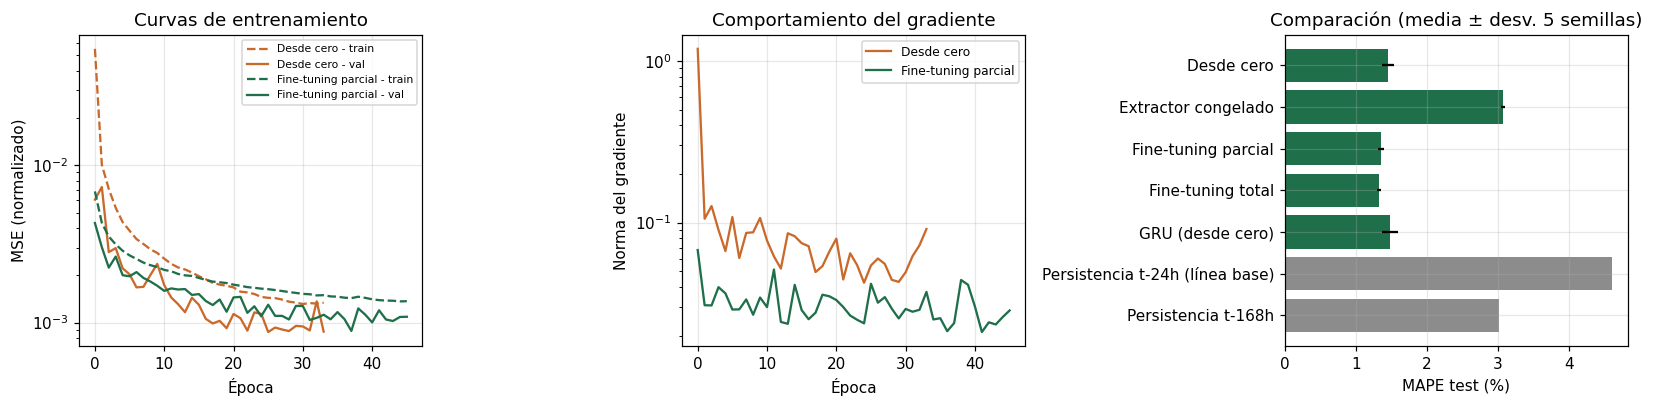

In [27]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
# (a) curvas de entrenamiento y validación (semilla 0)
for modo, c in [('Desde cero', '#c96a2b'), ('Fine-tuning parcial', '#1f6f4a')]:
    h = hists[(modo, SEMILLAS[0])]
    ax[0].plot(h['train'], color=c, ls='--', label=f'{modo} - train'); ax[0].plot(h['val'], color=c, label=f'{modo} - val')
ax[0].set_yscale('log'); ax[0].set_xlabel('Época'); ax[0].set_ylabel('MSE (normalizado)'); ax[0].set_title('Curvas de entrenamiento'); ax[0].legend(fontsize=7)
# (b) norma del gradiente
for modo, c in [('Desde cero', '#c96a2b'), ('Fine-tuning parcial', '#1f6f4a')]:
    ax[1].plot(hists[(modo, SEMILLAS[0])]['grad'], color=c, label=modo)
ax[1].set_yscale('log'); ax[1].set_xlabel('Época'); ax[1].set_ylabel('Norma del gradiente'); ax[1].set_title('Comportamiento del gradiente'); ax[1].legend(fontsize=8)
# (c) comparación de MAPE en test con barras de error (5 semillas)
nombres = list(resumen.index); vals = resumen['MAPE'].values; err = resumen['MAPE_std'].fillna(0).values
ax[2].barh(nombres, vals, xerr=err, color=['#1f6f4a']*5 + ['#8c8c8c']*2)
ax[2].set_xlabel('MAPE test (%)'); ax[2].set_title('Comparación (media ± desv. 5 semillas)'); ax[2].invert_yaxis()
plt.tight_layout(); plt.savefig('fig6_dinamica_y_comparacion.png', dpi=160); plt.show()

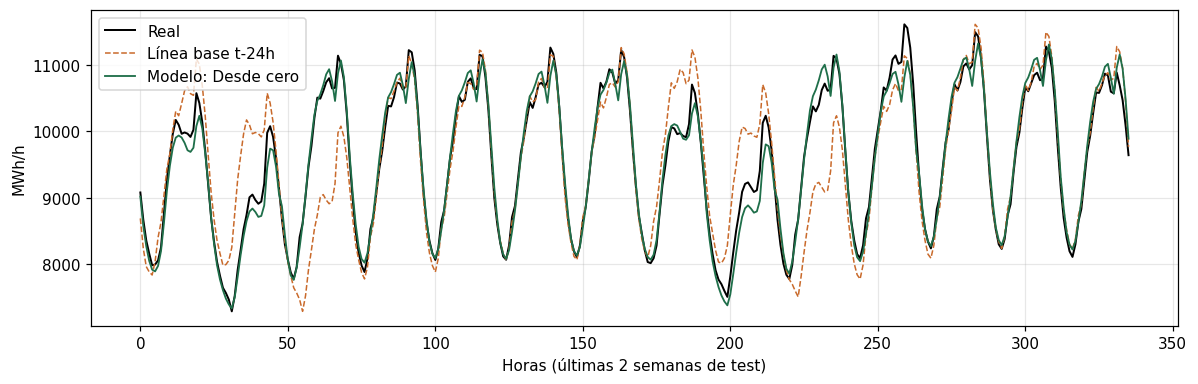

In [28]:
# Predicción vs realidad en las últimas 2 semanas de test
m = modelo0[mejor]; P = predecir(m, Wte_l)*rg_l[0] + mn_l[0]
k = 14
yy = y_real[-k:].ravel(); pp = P[-k:].ravel(); bb = loc.values[ix[-k:] - 24].ravel()
fig, a = plt.subplots(figsize=(11, 3.6))
a.plot(yy, 'k', lw=1.3, label='Real'); a.plot(bb, color='#c96a2b', ls='--', lw=1, label='Línea base t-24h'); a.plot(pp, color='#1f6f4a', lw=1.2, label=f'Modelo: {mejor}')
a.set_xlabel('Horas (últimas 2 semanas de test)'); a.set_ylabel('MWh/h'); a.legend(); plt.tight_layout()
plt.savefig('fig7_pronostico_final.png', dpi=160); plt.show()